# F160W

Target RA = 245.109310 deg
Target DEC = 12.061300 deg
Cutout RA = 245.109310 deg
Cutout DEC = 12.061300 deg


/gpfs/scratch/rmbrady/dolphin/dolphin/preprocessing/image_cutout.py:236: RuntimeWarning: divide by zero encountered in log10
  np.log10(noise_map * mask),


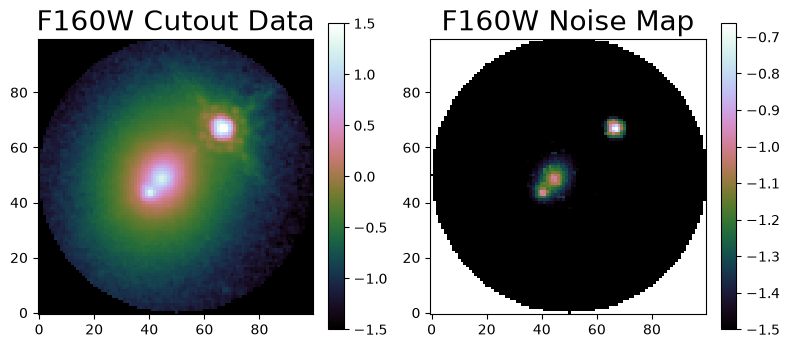

In [2]:
from dolphin.preprocessing.image_cutout import ImageCutout
import numpy as np
import matplotlib.pyplot as plt

io_directory="starred_models"
lens_name="J1620+1203"
data_band="F160W"
full_image_file=f"full_data/full_image_{lens_name}_{data_band}.fits"
weight_image_file=f"full_data/weight_image_{lens_name}_{data_band}.fits"

ImageCutout = ImageCutout(io_directory=io_directory,
          lens_name=lens_name,
          data_band=data_band,
          instrument="HST",
          full_image_file=full_image_file,
          weight_image_file=weight_image_file
         )

kwargs_mask=[{"type": "circle", "center": (50, 50), "radius": 50, "invert": False},]

ImageCutout.make_image_cutout(cutout_scale=100,
                              center_shift_arcsec=(0, 0),
                              kwargs_mask=kwargs_mask,
                              vmin=-1.5,
                              save=False
                             )

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 255ms/step


/var/folders/74/9yc0dt9d53z15d2qpmgpxv4h0000gn/T/ipykernel_84455/975679941.py:28: RuntimeWarning: invalid value encountered in log10
  axes[0].imshow(np.log10(image), origin="lower", cmap="cubehelix")
/var/folders/74/9yc0dt9d53z15d2qpmgpxv4h0000gn/T/ipykernel_84455/975679941.py:38: RuntimeWarning: invalid value encountered in log10
  axes[2].matshow(np.log10(image), origin="lower", cmap="cubehelix")


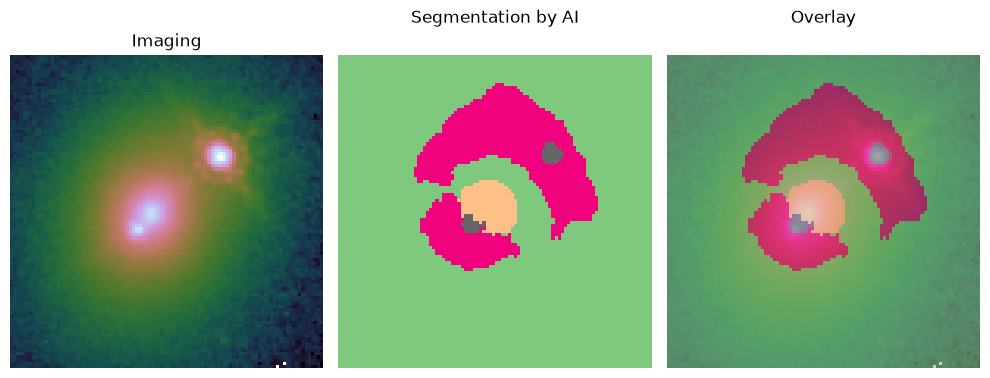

In [ ]:
from dolphin.ai import Vision
from dolphin.ai import Modeler

vision = Vision(io_directory_path=io_directory, source_type="quasar")
segementation = vision.create_segmentation_for_single_lens(lens_name, data_band)
# above line will save the segmentation result in output/

"""
Obtain initial coordinate guesses by saving the Modeler outputs to
a config file. This will overwrite the current one.

modeler = Modeler(io_directory_path=io_directory, source_type="quasar")
modeler.create_config_for_single_lens(
    lens_name,
    data_band,
)
# above line will save the config file in settings/ and a mask in
# output/masks/ 
"""

image = vision.get_image_data(lens_name, data_band).get_image()

fig, axes = plt.subplots(1, 3, figsize=(10, 5))

axes[0].imshow(np.log10(image), origin="lower", cmap="cubehelix")
axes[0].set_title("Imaging")
axes[0].axis("off")

cmap = "Accent"
# use qualitaive cmap for the segmentation plot
axes[1].matshow(segementation, origin="lower", cmap=cmap)
axes[1].set_title("Segmentation by AI")
axes[1].axis("off")

axes[2].matshow(np.log10(image), origin="lower", cmap="cubehelix")
axes[2].matshow(segementation, origin="lower", cmap=cmap, alpha=0.6)
axes[2].set_title("Overlay")
axes[2].axis("off")

fig.tight_layout()

Found 3 candidate objects!


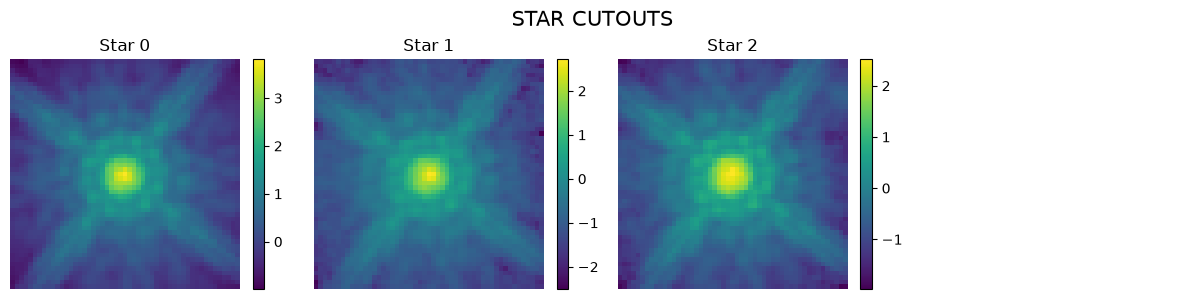

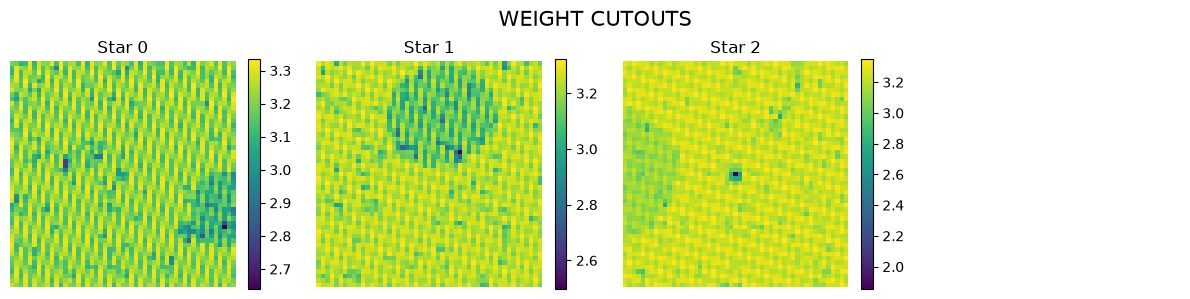

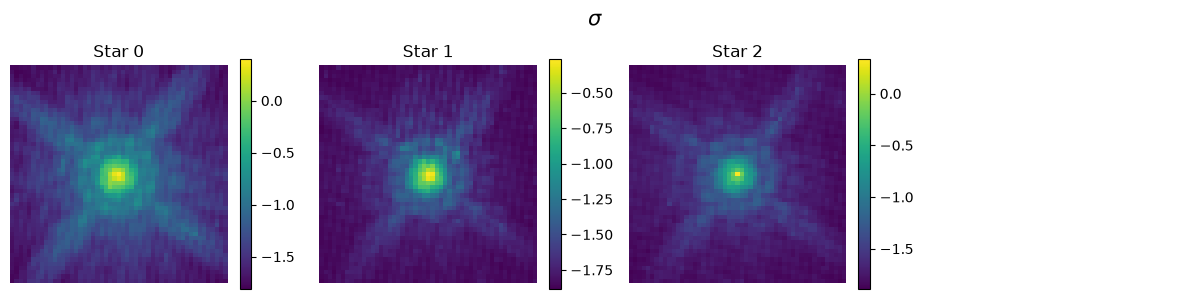

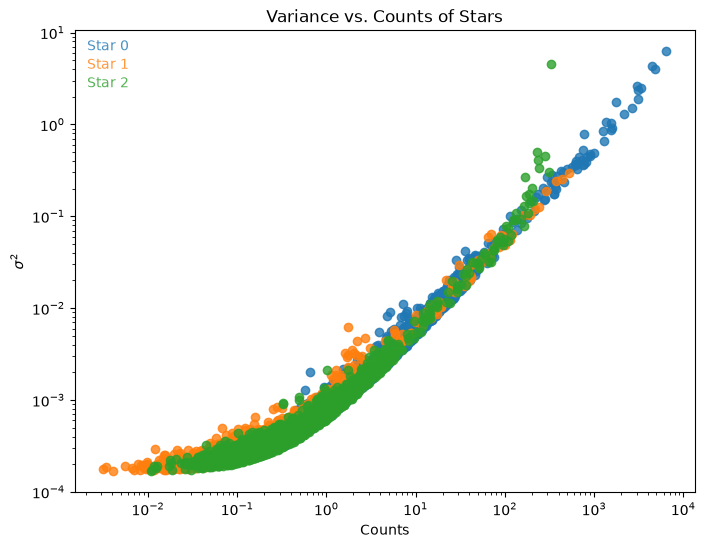

/gpfs/scratch/rmbrady/dolphin/dolphin/preprocessing/psf.py:729: RuntimeWarning: invalid value encountered in log10
  plt_data = np.log10(data_full + 0.1)


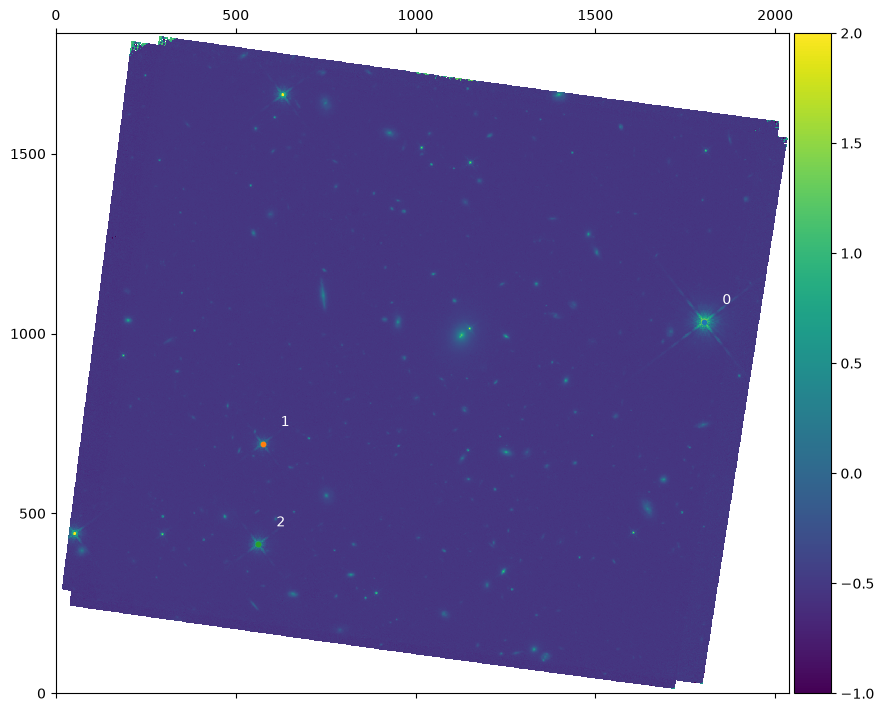

In [3]:
from dolphin.preprocessing.psf import PSF

psf = PSF(io_directory=io_directory,
          lens_name=lens_name,
          data_band=data_band,
          instrument="HST",
          full_image_file=full_image_file,
          weight_image_file=weight_image_file
         )

star_data_list, weight_data_list, noise_map_list = psf.get_psf_candidates(threshold_over_background=5000, 
                                                                          cutout_size=51,
                                                                          include_specific=[0, 3, 4],
                                                                          save=False
                                                                        )

/gpfs/home/rmbrady/miniconda3/envs/dolphin/lib/python3.11/site-packages/starred/optim/optimization.py:181: UserWarning: You are using an unconstrained optimiser. Bounds are ignored.
  warnings.warn('You are using an unconstrained optimiser. Bounds are ignored.')
/gpfs/home/rmbrady/miniconda3/envs/dolphin/lib/python3.11/site-packages/starred/utils/noise_utils.py:53: RuntimeWarning: Mean of empty slice
  noise_map = np.nanmean(centered_masked_noise_maps, axis=0)
optax.adabelief: 100%|████████████████████| 3000/3000 [00:14<00:00, 203.78it/s]


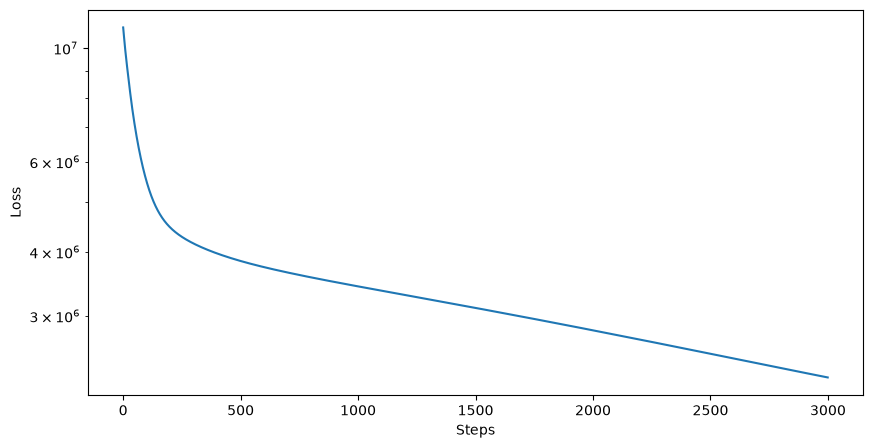

/gpfs/scratch/rmbrady/dolphin/dolphin/preprocessing/psf.py:927: RuntimeWarning: invalid value encountered in log10
  im_psf = ax[0].imshow(np.log10(psf_guess), origin="lower", cmap="viridis")


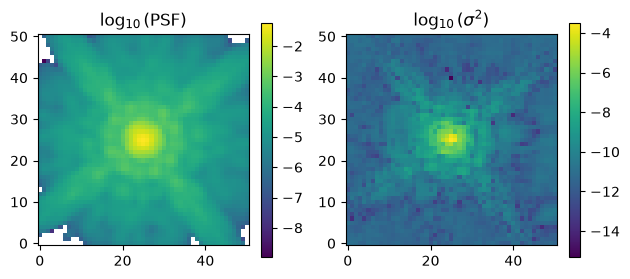

/gpfs/scratch/rmbrady/dolphin/dolphin/preprocessing/psf.py:940: RuntimeWarning: divide by zero encountered in log10
  ax[0].imshow(np.log10(psf_cut))
/gpfs/scratch/rmbrady/dolphin/dolphin/preprocessing/psf.py:946: RuntimeWarning: divide by zero encountered in log10
  ax[1].imshow(np.log10(variance_map_cut))


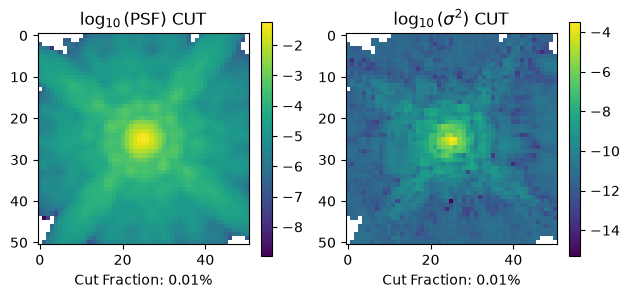

In [4]:
psf_starred, variance_map = psf.make_psf_starred(star_data_list=star_data_list,
                                               noise_map_list=noise_map_list,
                                               subsampling_factor=1,
                                               cut_threshold=1.7e-20,
                                               regularization_strength_scales=2.,
                                               regularization_strength_hf=2.,
                                               max_iterations=3000,
                                               save=True
                                            )

/gpfs/scratch/rmbrady/dolphin/dolphin/preprocessing/psf.py:899: RuntimeWarning: divide by zero encountered in log10
  im_variance = ax[1].imshow(np.log10(variance_map), origin="lower")


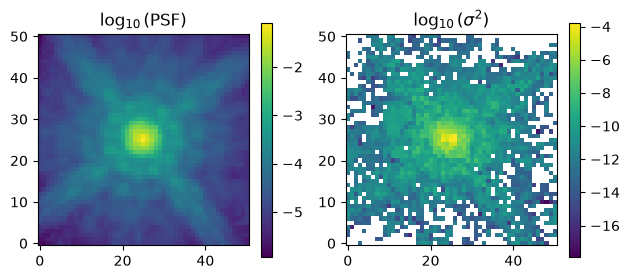

/gpfs/scratch/rmbrady/dolphin/dolphin/preprocessing/psf.py:912: UserWarning: Adding colorbar to a different Figure <Figure size 640x480 with 4 Axes> than <Figure size 640x480 with 3 Axes> which fig.colorbar is called on.
  fig.colorbar(im_psf, ax=ax[0], fraction=0.05)
/gpfs/scratch/rmbrady/dolphin/dolphin/preprocessing/psf.py:914: RuntimeWarning: divide by zero encountered in log10
  ax[1].imshow(np.log10(variance_map_cut))
/gpfs/scratch/rmbrady/dolphin/dolphin/preprocessing/psf.py:917: UserWarning: Adding colorbar to a different Figure <Figure size 640x480 with 4 Axes> than <Figure size 640x480 with 4 Axes> which fig.colorbar is called on.
  fig.colorbar(im_variance, ax=ax[1], fraction=0.05)


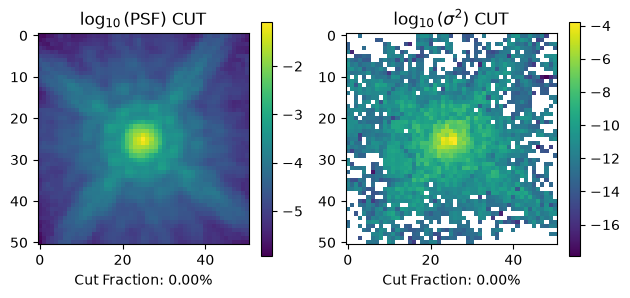

In [5]:
psf = PSF(io_directory="psfr_models",
          lens_name=lens_name,
          data_band=data_band,
          instrument="HST",
          full_image_file=full_image_file,
          weight_image_file=weight_image_file
         )

psf_psfr, variance_map_psfr = psf.make_psf_psfr(star_data_list=star_data_list,
                                                noise_map_list=noise_map_list,
                                                oversampling=1,
                                                cut_threshold=1.7e-20,
                                                save=True
                                               )

# F814W

Target RA = 245.109310 deg
Target DEC = 12.061300 deg
Cutout RA = 245.109310 deg
Cutout DEC = 12.061300 deg


/gpfs/scratch/rmbrady/dolphin/dolphin/preprocessing/image_cutout.py:236: RuntimeWarning: divide by zero encountered in log10
  np.log10(noise_map * mask),


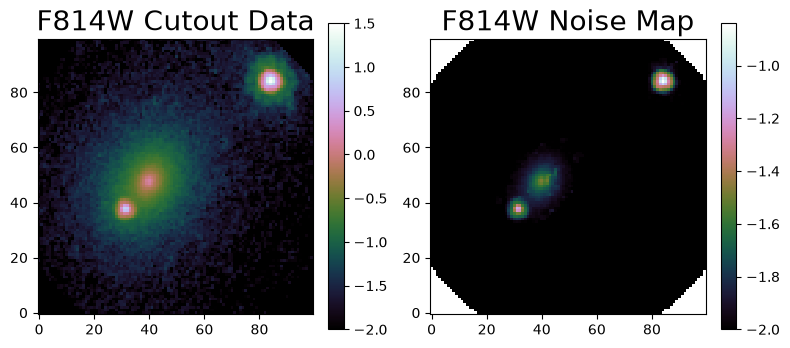

In [6]:
from dolphin.preprocessing.image_cutout import ImageCutout

lens_name="J1620+1203"
io_directory="starred"
data_band="F814W"
full_image_file=f"full_data/full_image_{lens_name}_{data_band}.fits"
weight_image_file=f"full_data/weight_image_{lens_name}_{data_band}.fits"

ImageCutout = ImageCutout(io_directory=io_directory,
          lens_name=lens_name,
          data_band=data_band,
          instrument="HST",
          full_image_file=full_image_file,
          weight_image_file=weight_image_file
         )

kwargs_mask=[{"type": "circle", "center": (50, 50), "radius": 60, "invert": False},]

ImageCutout.make_image_cutout(cutout_scale=100,
                              center_shift_arcsec=(0, 0),
                              kwargs_mask=kwargs_mask,
                              vmin=-2.,
                              save=False
                             )

Found 3 candidate objects!


/gpfs/scratch/rmbrady/dolphin/dolphin/preprocessing/psf.py:621: RuntimeWarning: invalid value encountered in log10
  im_star = ax[i].imshow(np.log10(star_exposures[i].data), cmap="viridis")


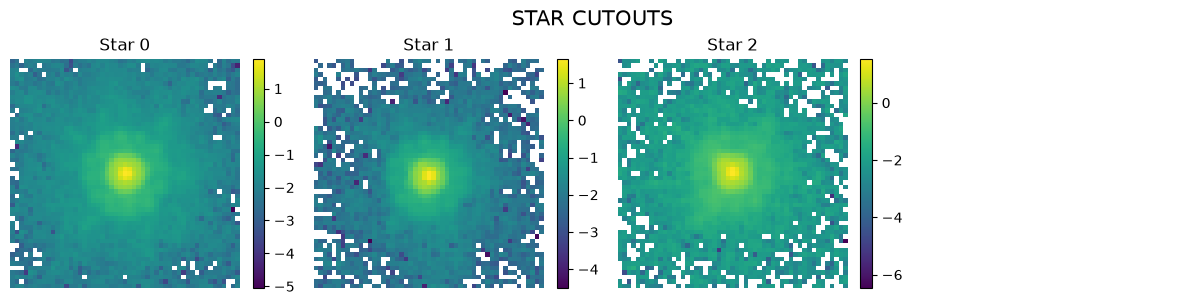

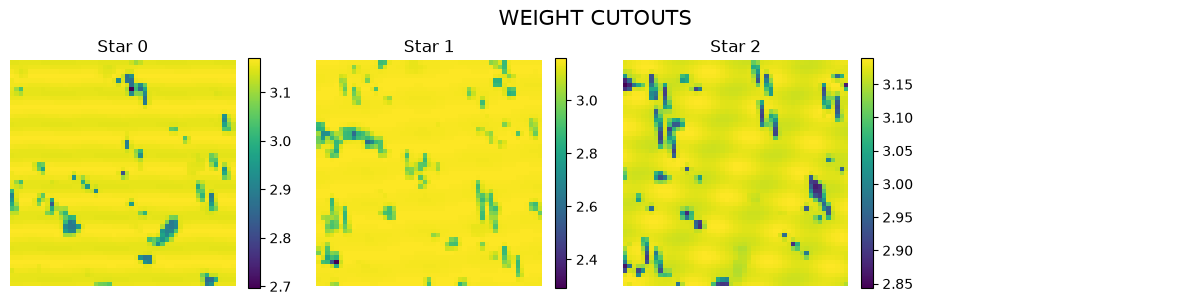

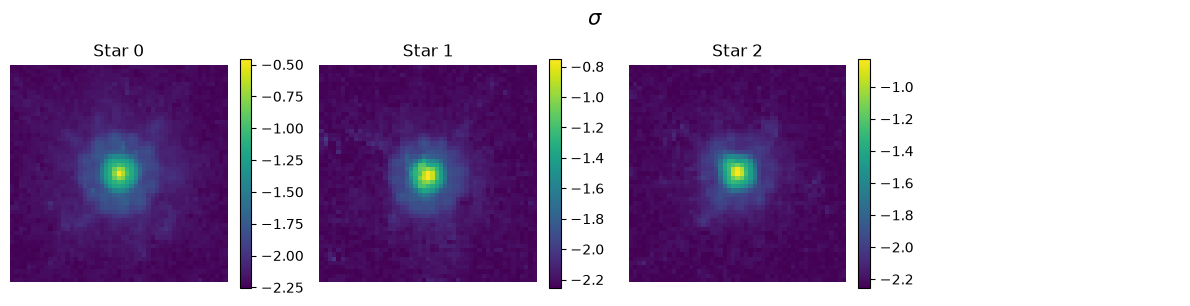

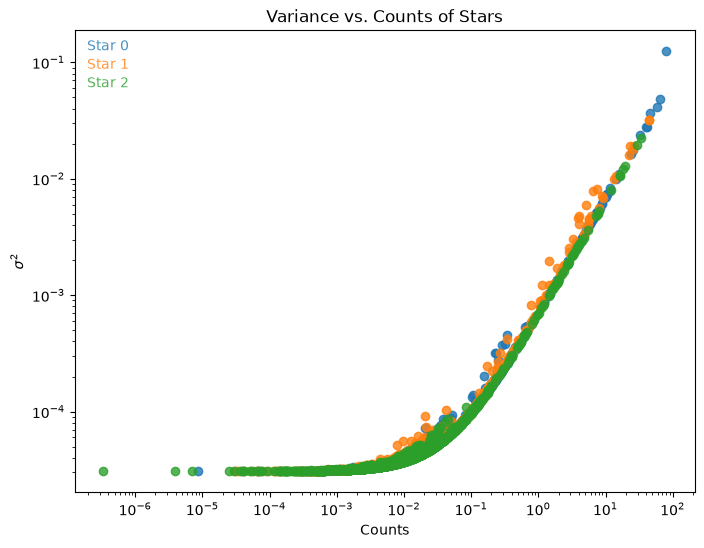

/gpfs/scratch/rmbrady/dolphin/dolphin/preprocessing/psf.py:729: RuntimeWarning: invalid value encountered in log10
  plt_data = np.log10(data_full + 0.1)


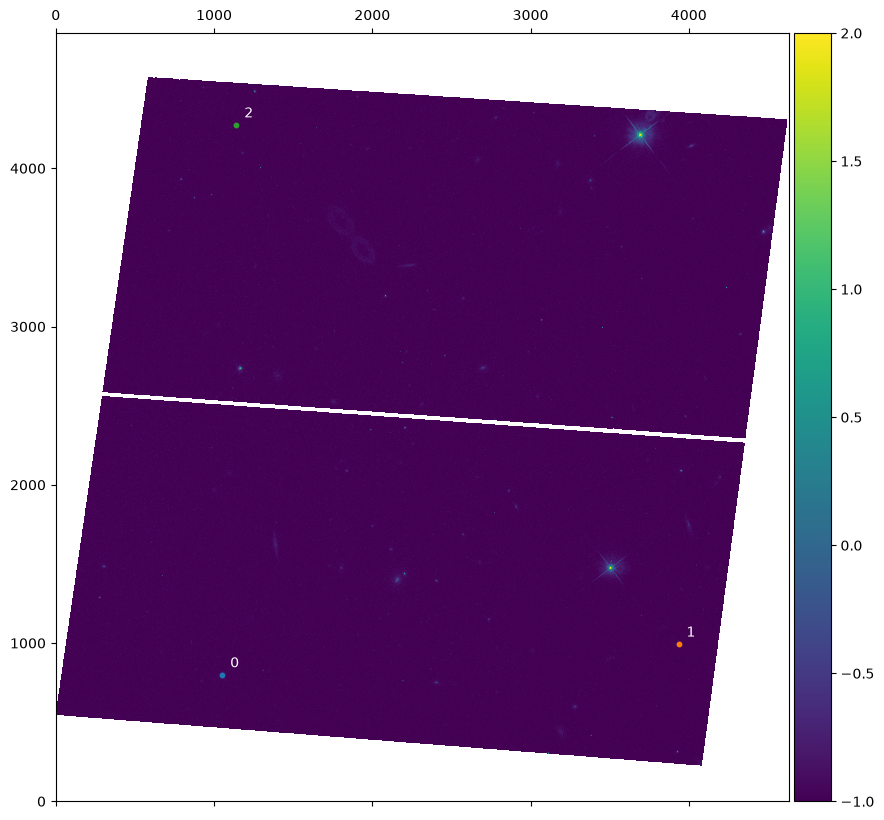

In [7]:
from dolphin.preprocessing.psf import PSF

psf = PSF(io_directory=io_directory,
          lens_name=lens_name,
          data_band=data_band,
          instrument="HST",
          full_image_file=full_image_file,
          weight_image_file=weight_image_file
         )

star_data_list, weight_data_list, noise_map_list = psf.get_psf_candidates(threshold_over_background=2000, 
                                                                          cutout_size=51,
                                                                          include_specific=[6, 10, 15],
                                                                          save=True
                                                                        )

/gpfs/home/rmbrady/miniconda3/envs/dolphin/lib/python3.11/site-packages/starred/optim/optimization.py:181: UserWarning: You are using an unconstrained optimiser. Bounds are ignored.
  warnings.warn('You are using an unconstrained optimiser. Bounds are ignored.')
/gpfs/home/rmbrady/miniconda3/envs/dolphin/lib/python3.11/site-packages/starred/utils/noise_utils.py:53: RuntimeWarning: Mean of empty slice
  noise_map = np.nanmean(centered_masked_noise_maps, axis=0)
optax.adabelief: 100%|████████████████████| 3000/3000 [00:14<00:00, 204.74it/s]


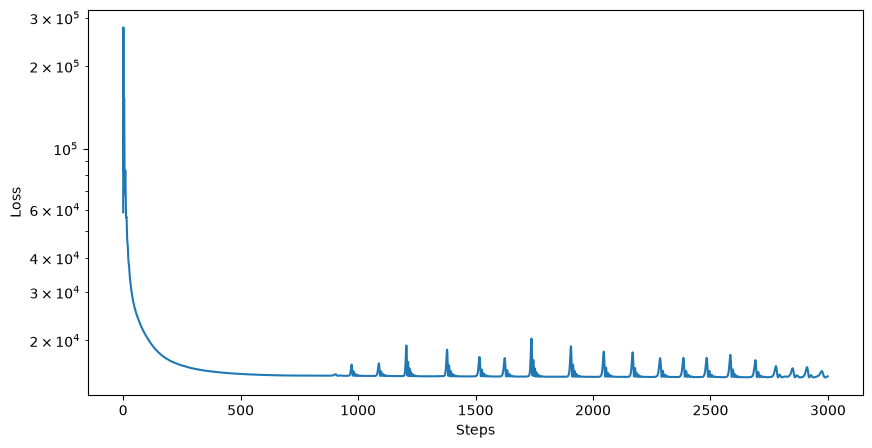

/gpfs/scratch/rmbrady/dolphin/dolphin/preprocessing/psf.py:927: RuntimeWarning: invalid value encountered in log10
  im_psf = ax[0].imshow(np.log10(psf_guess), origin="lower", cmap="viridis")


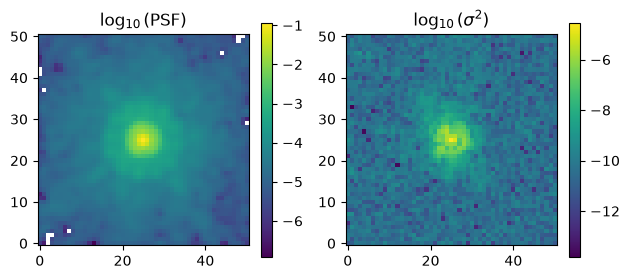

/gpfs/scratch/rmbrady/dolphin/dolphin/preprocessing/psf.py:940: RuntimeWarning: divide by zero encountered in log10
  ax[0].imshow(np.log10(psf_cut))
/gpfs/scratch/rmbrady/dolphin/dolphin/preprocessing/psf.py:946: RuntimeWarning: divide by zero encountered in log10
  ax[1].imshow(np.log10(variance_map_cut))


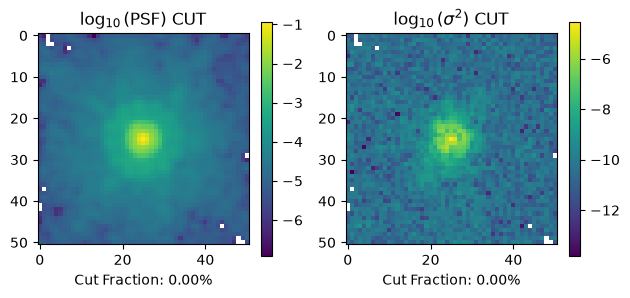

In [8]:
psf_starred, variance_map = psf.make_psf_starred(star_data_list=star_data_list,
                                               noise_map_list=noise_map_list,
                                               subsampling_factor=1,
                                               cut_threshold=1.7e-20,
                                               regularization_strength_scales=2.,
                                               regularization_strength_hf=2.,
                                               max_iterations=3000,
                                               save=True
                                            )

/gpfs/scratch/rmbrady/dolphin/dolphin/preprocessing/psf.py:895: RuntimeWarning: invalid value encountered in log10
  im_psf = ax[0].imshow(np.log10(psf_guess), origin="lower", cmap="viridis")
/gpfs/scratch/rmbrady/dolphin/dolphin/preprocessing/psf.py:899: RuntimeWarning: divide by zero encountered in log10
  im_variance = ax[1].imshow(np.log10(variance_map), origin="lower")


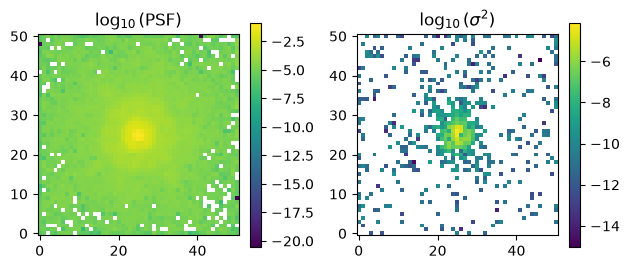

/gpfs/scratch/rmbrady/dolphin/dolphin/preprocessing/psf.py:908: RuntimeWarning: divide by zero encountered in log10
  ax[0].imshow(np.log10(psf_cut))
/gpfs/scratch/rmbrady/dolphin/dolphin/preprocessing/psf.py:912: UserWarning: Adding colorbar to a different Figure <Figure size 640x480 with 4 Axes> than <Figure size 640x480 with 3 Axes> which fig.colorbar is called on.
  fig.colorbar(im_psf, ax=ax[0], fraction=0.05)
/gpfs/scratch/rmbrady/dolphin/dolphin/preprocessing/psf.py:914: RuntimeWarning: divide by zero encountered in log10
  ax[1].imshow(np.log10(variance_map_cut))
/gpfs/scratch/rmbrady/dolphin/dolphin/preprocessing/psf.py:917: UserWarning: Adding colorbar to a different Figure <Figure size 640x480 with 4 Axes> than <Figure size 640x480 with 4 Axes> which fig.colorbar is called on.
  fig.colorbar(im_variance, ax=ax[1], fraction=0.05)


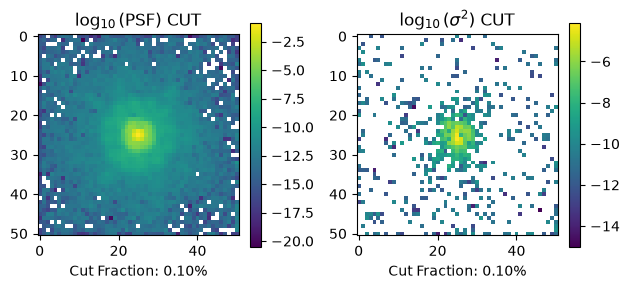

In [9]:
psf = PSF(io_directory="psfr_models",
          lens_name=lens_name,
          data_band=data_band,
          instrument="HST",
          full_image_file=full_image_file,
          weight_image_file=weight_image_file
         )

psf_psfr, variance_map_psfr = psf.make_psf_psfr(star_data_list=star_data_list,
                                                noise_map_list=noise_map_list,
                                                oversampling=1,
                                                cut_threshold=1.7e-20,
                                                save=True
                                               )

# F475X

Target RA = 245.109310 deg
Target DEC = 12.061300 deg
Cutout RA = 245.109310 deg
Cutout DEC = 12.061300 deg


/gpfs/scratch/rmbrady/dolphin/dolphin/preprocessing/image_cutout.py:236: RuntimeWarning: divide by zero encountered in log10
  np.log10(noise_map * mask),


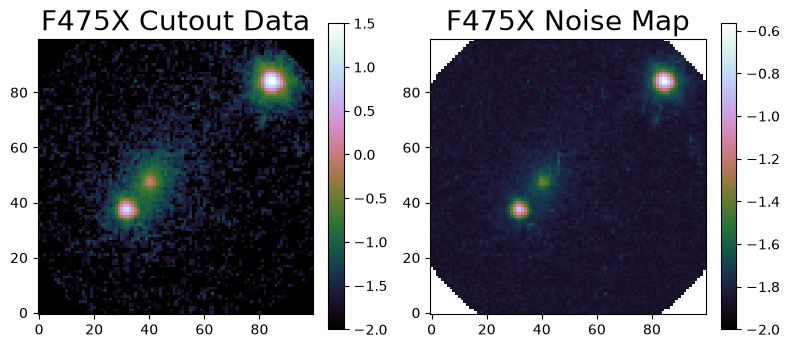

In [10]:
from dolphin.preprocessing.image_cutout import ImageCutout

lens_name="J1620+1203"
io_directory="starred_models"
data_band="F475X"
full_image_file=f"full_data/full_image_{lens_name}_{data_band}.fits"
weight_image_file=f"full_data/weight_image_{lens_name}_{data_band}.fits"

ImageCutout = ImageCutout(io_directory=io_directory,
          lens_name=lens_name,
          data_band=data_band,
          instrument="HST",
          full_image_file=full_image_file,
          weight_image_file=weight_image_file
         )

kwargs_mask=[{"type": "circle", "center": (50, 50), "radius": 60, "invert": False},]

ImageCutout.make_image_cutout(cutout_scale=100,
                              center_shift_arcsec=(0, 0),
                              kwargs_mask=kwargs_mask,
                              vmin=-2,
                              save=False
                             )

Found 5 candidate objects!


/gpfs/scratch/rmbrady/dolphin/dolphin/preprocessing/psf.py:621: RuntimeWarning: invalid value encountered in log10
  im_star = ax[i].imshow(np.log10(star_exposures[i].data), cmap="viridis")


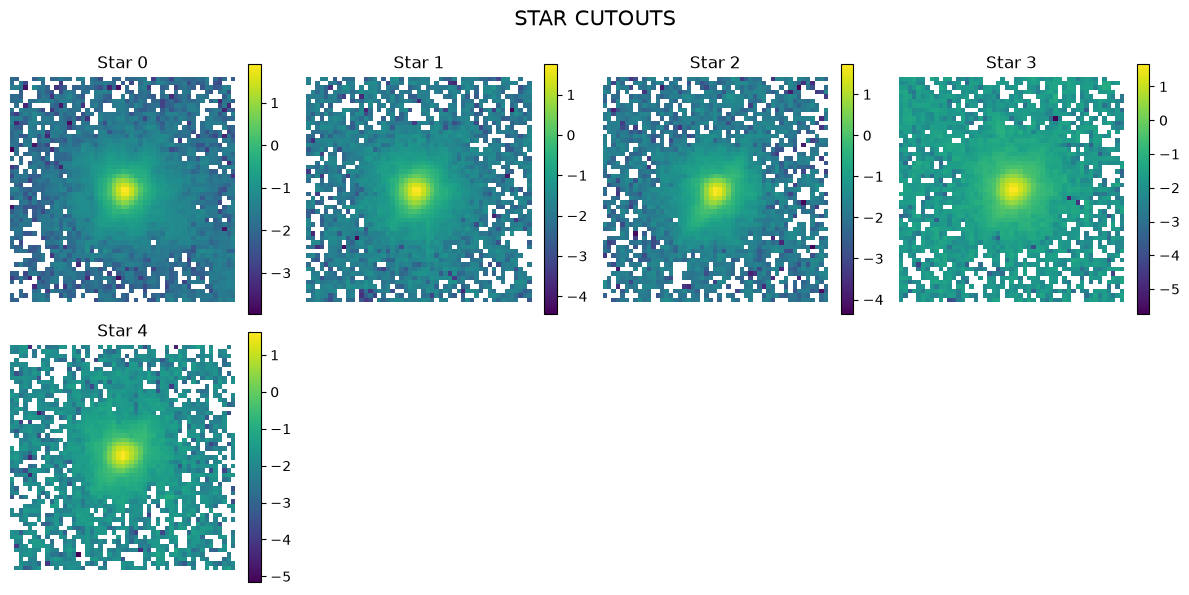

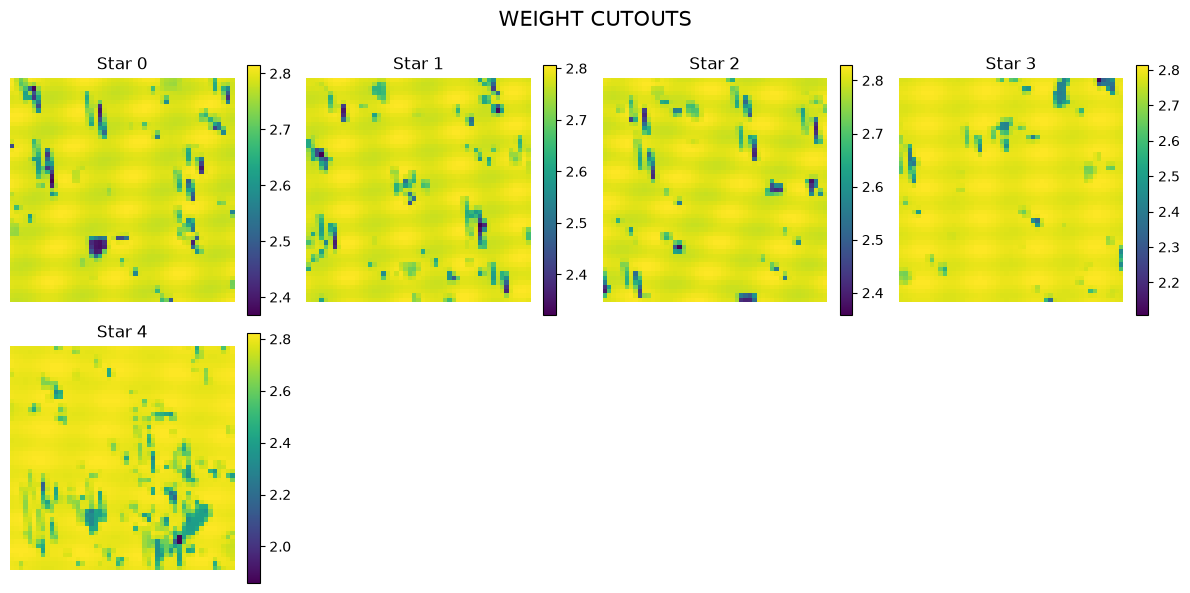

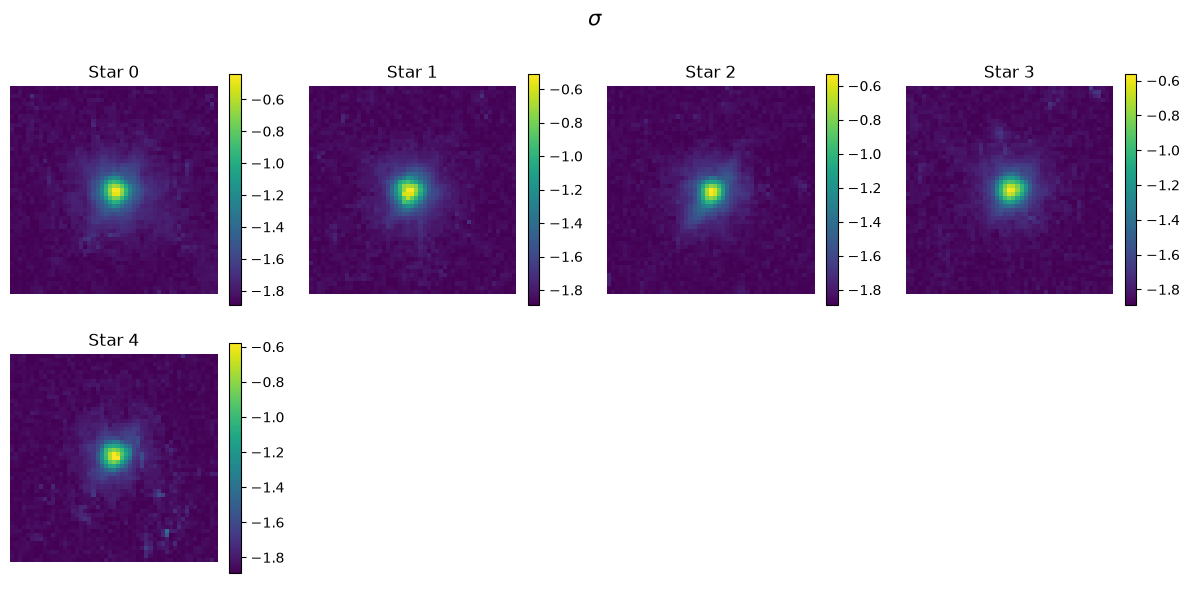

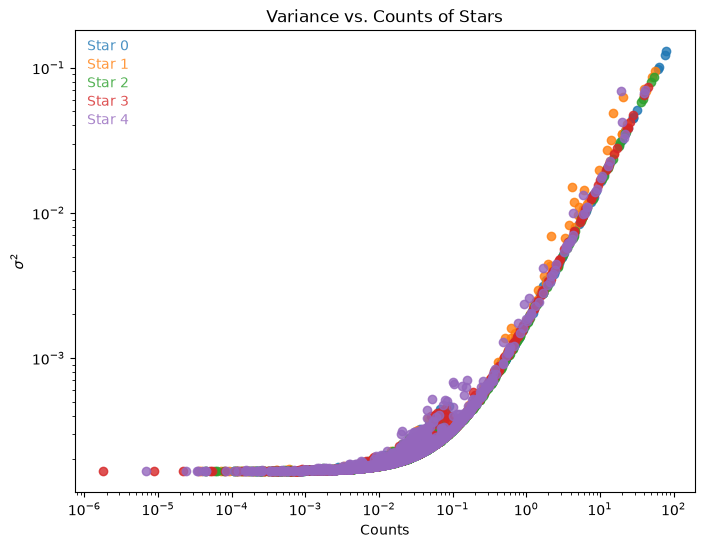

/gpfs/scratch/rmbrady/dolphin/dolphin/preprocessing/psf.py:729: RuntimeWarning: invalid value encountered in log10
  plt_data = np.log10(data_full + 0.1)


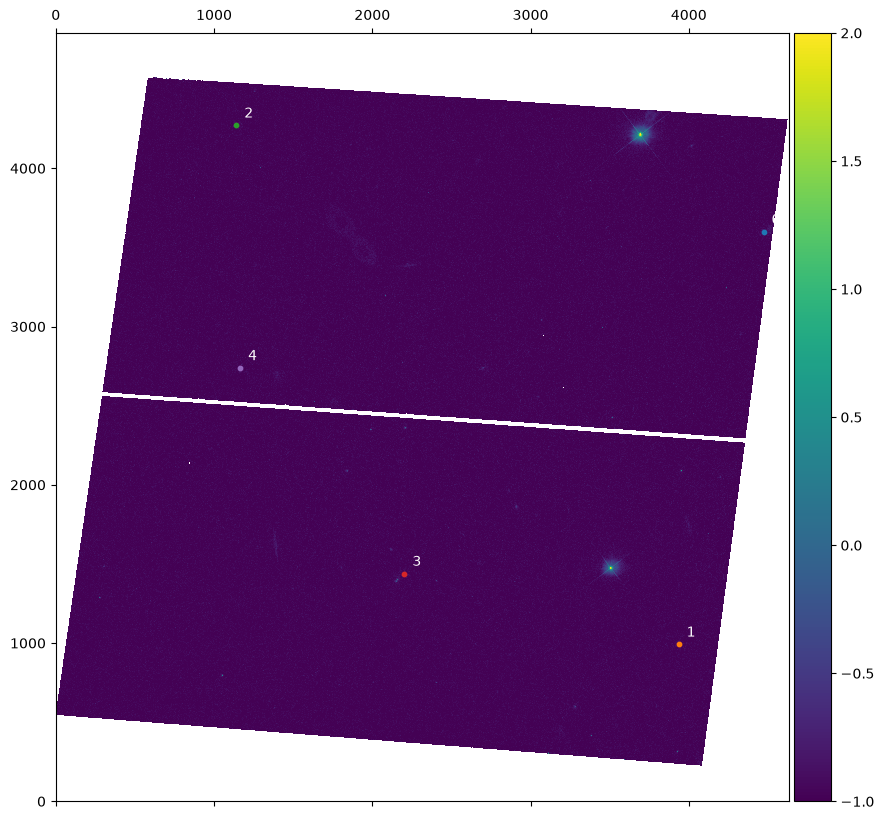

In [11]:
from dolphin.preprocessing.psf import PSF

psf = PSF(io_directory=io_directory,
          lens_name=lens_name,
          data_band=data_band,
          instrument="HST",
          full_image_file=full_image_file,
          weight_image_file=weight_image_file
         )

star_data_list, weight_data_list, noise_map_list = psf.get_psf_candidates(threshold_over_background=2000, 
                                                                          cutout_size=51,
                                                                          include_specific=[7, 8, 9, 10, 12],
                                                                          save=False
                                                                        )

/gpfs/home/rmbrady/miniconda3/envs/dolphin/lib/python3.11/site-packages/starred/optim/optimization.py:181: UserWarning: You are using an unconstrained optimiser. Bounds are ignored.
  warnings.warn('You are using an unconstrained optimiser. Bounds are ignored.')
/gpfs/home/rmbrady/miniconda3/envs/dolphin/lib/python3.11/site-packages/starred/utils/noise_utils.py:53: RuntimeWarning: Mean of empty slice
  noise_map = np.nanmean(centered_masked_noise_maps, axis=0)
optax.adabelief: 100%|████████████████████| 3000/3000 [00:15<00:00, 196.89it/s]


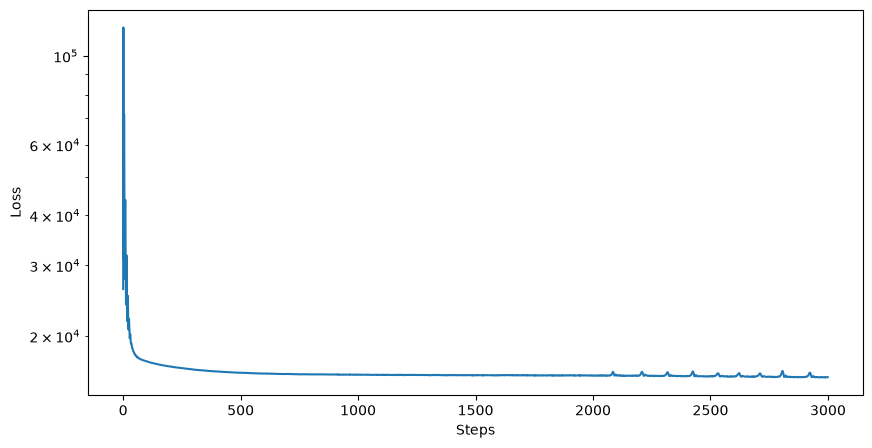

/gpfs/scratch/rmbrady/dolphin/dolphin/preprocessing/psf.py:927: RuntimeWarning: invalid value encountered in log10
  im_psf = ax[0].imshow(np.log10(psf_guess), origin="lower", cmap="viridis")


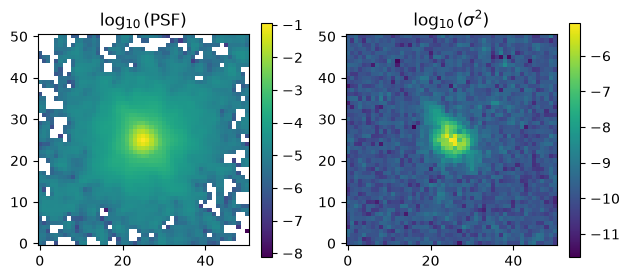

/gpfs/scratch/rmbrady/dolphin/dolphin/preprocessing/psf.py:940: RuntimeWarning: divide by zero encountered in log10
  ax[0].imshow(np.log10(psf_cut))
/gpfs/scratch/rmbrady/dolphin/dolphin/preprocessing/psf.py:946: RuntimeWarning: divide by zero encountered in log10
  ax[1].imshow(np.log10(variance_map_cut))


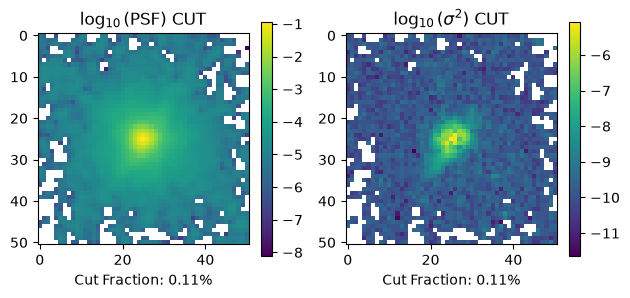

In [12]:
psf_starred, variance_map = psf.make_psf_starred(star_data_list=star_data_list,
                                               noise_map_list=noise_map_list,
                                               subsampling_factor=1,
                                               cut_threshold=1.7e-20,
                                               regularization_strength_scales=2.,
                                               regularization_strength_hf=2.,
                                               max_iterations=3000,
                                               save=True
                                            )

/gpfs/scratch/rmbrady/dolphin/dolphin/preprocessing/psf.py:895: RuntimeWarning: invalid value encountered in log10
  im_psf = ax[0].imshow(np.log10(psf_guess), origin="lower", cmap="viridis")
/gpfs/scratch/rmbrady/dolphin/dolphin/preprocessing/psf.py:899: RuntimeWarning: divide by zero encountered in log10
  im_variance = ax[1].imshow(np.log10(variance_map), origin="lower")


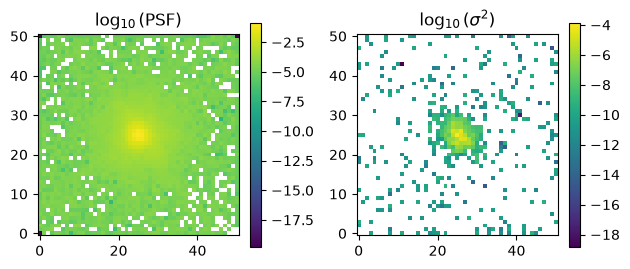

/gpfs/scratch/rmbrady/dolphin/dolphin/preprocessing/psf.py:908: RuntimeWarning: divide by zero encountered in log10
  ax[0].imshow(np.log10(psf_cut))
/gpfs/scratch/rmbrady/dolphin/dolphin/preprocessing/psf.py:912: UserWarning: Adding colorbar to a different Figure <Figure size 640x480 with 4 Axes> than <Figure size 640x480 with 3 Axes> which fig.colorbar is called on.
  fig.colorbar(im_psf, ax=ax[0], fraction=0.05)
/gpfs/scratch/rmbrady/dolphin/dolphin/preprocessing/psf.py:914: RuntimeWarning: divide by zero encountered in log10
  ax[1].imshow(np.log10(variance_map_cut))
/gpfs/scratch/rmbrady/dolphin/dolphin/preprocessing/psf.py:917: UserWarning: Adding colorbar to a different Figure <Figure size 640x480 with 4 Axes> than <Figure size 640x480 with 4 Axes> which fig.colorbar is called on.
  fig.colorbar(im_variance, ax=ax[1], fraction=0.05)


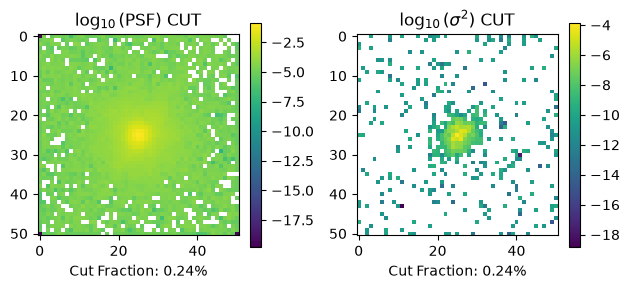

In [13]:
psf = PSF(io_directory="psfr_models",
          lens_name=lens_name,
          data_band=data_band,
          instrument="HST",
          full_image_file=full_image_file,
          weight_image_file=weight_image_file
         )

psf_psfr, variance_map_psfr = psf.make_psf_psfr(star_data_list=star_data_list,
                                                noise_map_list=noise_map_list,
                                                oversampling=1,
                                                cut_threshold=1.7e-20,
                                                save=True
                                               )